# Tarea 1 · Fritz renegocia

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica · UNAM, Instituto de Geología · noviembre de 2026
**Entrega:** antes del martes 10 de noviembre · **Tiempo estimado:** 60 minutos · **Valor:** 10 puntos (8 automáticos, 2 de interpretación)

**Para aprobar:** este cuaderno se aprueba con **6 de 10** puntos. Con **2 de los 4 cuadernos** aprobados, el examen del curso está aprobado.

---

## El problema

Fritz Nowak tiene tres pozos en un acuífero confinado, el mismo de la sesión. Este año cambiaron dos cosas:

1. El **contrato del pozo 3** se renegoció: ahora bombea una cantidad fija distinta, **tu P3**.
2. La autoridad ambiental fijó un **nuevo límite de abatimiento en el humedal**: **tu S_HUM**.

Las demás reglas siguen: en ningún pozo el nivel puede bajar más de **3 m**, y ninguna bomba da más de 1 000 m³/d.

Fritz quiere tres respuestas, y este cuaderno las construye por etapas:

| Etapa | Pregunta de Fritz |
|---|---|
| 1 | «Antes de calcular nada: ¿estas tres ideas mías respetan las reglas?» |
| 2 | «¿Cuánto abate cada pozo por cada metro cúbico al día que bombea?» |
| 3 | «¿Cuánto puedo bombear en total ahora, y qué es lo que me frena?» |
| 4 | «Mi vecino exige proteger su pozo. ¿Cuánto me cuesta?» |
| 5 | «Explícamelo en palabras.» |

### Cómo se trabaja

- **Todo el código ya está escrito.** En cada celda hay dos partes: arriba, un recuadro **INGRESA AQUÍ LOS DATOS SOLICITADOS**, donde sustituyes los `...` por valores; abajo, una parte marcada **NO MODIFIQUES**, que se ejecuta sola y te muestra el resultado.
- Después de cada etapa hay una celda `grader.check(...)`: ejecútala y te dirá **al momento** si tus datos pasan las pruebas visibles. Si falla, corrige y vuelve a ejecutar. Las pruebas ocultas las corre el instructor al calificar.
- La etapa 5 se responde escribiendo en celdas de texto.
- Al terminar: menú **Ejecutar todo**, guarda el archivo como `Tarea_1_<tu nombre>.ipynb` y súbelo al formulario del curso.
- Usa el cuaderno de la práctica y las láminas. No uses el cuaderno de otra persona: sus números no son los tuyos y las pruebas lo detectan.

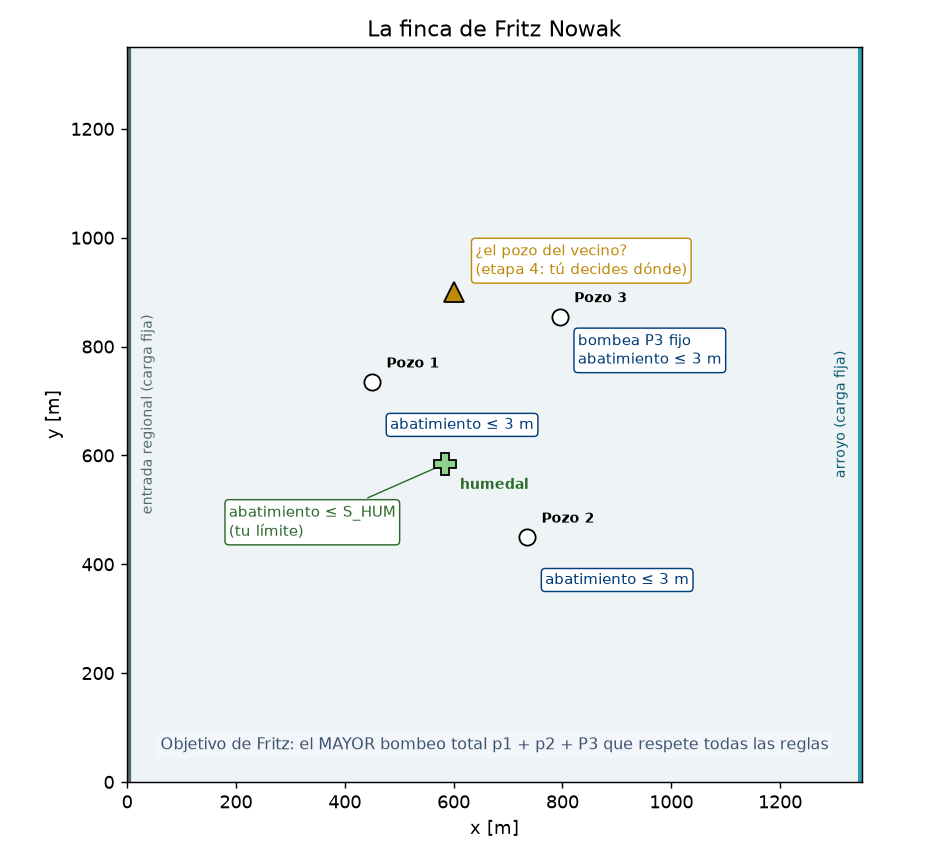

*La finca de Fritz: el agua entra por la izquierda, sale por el arroyo de la derecha; tres pozos, un humedal protegido, y en la etapa 4 un pozo de vecino cuya ubicación decides tú.*

In [ ]:
# Preparación (se ejecuta sola): carga las herramientas y el acuífero del curso. No hay nada que escribir aquí.
# Si esta celda tarda más de un minuto, mira cuál fue el último paso impreso y díselo al instructor.
import sys, os, glob
print("paso 1 de 5: localizando este cuaderno…", flush=True)
_ruta = os.path.abspath(globals().get("__vsc_ipynb_file__") or next(iter(sorted(glob.glob("Tarea_1*.ipynb"))), "Tarea_1.ipynb"))
print("          ", _ruta, flush=True)
try:
    import hidra
except ImportError:                      # hidra.py vive en la carpeta Curso_V3: la buscamos subiendo desde la carpeta de este cuaderno
    for _inicio in (os.path.dirname(_ruta), os.getcwd()):
        _d = _inicio
        for _ in range(6):
            if os.path.exists(os.path.join(_d, "hidra.py")):
                sys.path.insert(0, _d); break
            _d = os.path.dirname(_d)
print("paso 2 de 5: cargando numpy, scipy y matplotlib…", flush=True)
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt
print("paso 3 de 5: cargando hidra (el acuífero del curso)…", flush=True)
import hidra
print("paso 4 de 5: cargando otter (las comprobaciones)…", flush=True)
import otter
print("paso 5 de 5: preparando el calificador…", flush=True)
grader = otter.Notebook(_ruta)
print("Herramientas listas.")

## Etapa 0 · Los datos de Fritz (sin puntos, pero sin esto nada funciona)

**Problema.** El contrato nuevo del pozo 3 y el límite nuevo del humedal son distintos para cada estudiante: salen del correo con el que te inscribiste.

**Pregunta.** ¿Cuáles son mis reglas? Escribe tu correo y el cuaderno te dirá tu S_HUM y tu P3. **Anótalos**: aparecerán en todas las etapas.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tu correo de inscripción, entre comillas. Ejemplo: "ana.lopez@gmail.com"
IDENTIFICADOR = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
datos = hidra.datos_tarea(IDENTIFICADOR)
S_HUM = datos["s_max_humedal"]       # tu límite de abatimiento en el humedal [m]
P3 = datos["p3"]                     # tu demanda comprometida del pozo 3 [m³/d]
print("Tus reglas:")
print("  humedal: el nivel no puede bajar más de", S_HUM, "m")
print("  pozo 3:  bombea", P3, "m³/d, fijos")
print("  pozos:   el nivel no puede bajar más de 3 m en ninguno")

In [ ]:
grader.check("q0")

## Etapa 1 · Probar antes de calcular (1.5 puntos)

**Problema.** Fritz tiene tres ideas de cuánto bombear en los pozos 1 y 2 (el pozo 3 ya está fijo en tu P3). No sabe si respetan las reglas.

**Pregunta.** Propón tú esas tres ideas, una de cada tipo:

- `factible`: respeta **todas** las reglas (≤ 3 m en los tres pozos y ≤ S_HUM en el humedal);
- `rompe_pozo`: algún pozo pasa de 3 m;
- `rompe_humedal`: el humedal pasa de S_HUM, pero **ningún pozo** pasa de 3 m.

Escribe los dos bombeos de cada idea, ejecuta, mira la tabla y los mapas, y ajusta los números hasta que cada idea haga lo que dice su nombre.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Cada idea son tres bombeos en m³/d: [pozo 1, pozo 2, P3]. Cambia solo los dos primeros. Ejemplo: [250, 150, P3]
factible      = ...
rompe_pozo    = ...
rompe_humedal = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
decisiones = {"factible": factible, "rompe_pozo": rompe_pozo, "rompe_humedal": rompe_humedal}
resultados = {}
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, nombre in zip(ejes, decisiones):
    r = hidra.simular(decisiones[nombre])
    resultados[nombre] = r
    pozos_ok = (r.abatimiento_pozos <= 3).all()
    humedal_ok = r.abatimiento_humedal <= S_HUM
    print(nombre, "->", "bombeos", decisiones[nombre], "| abatimiento en pozos", np.round(r.abatimiento_pozos, 2), "m",
          "| humedal", round(r.abatimiento_humedal, 2), "m", "| pozos", "OK" if pozos_ok else "ROMPE", "| humedal", "OK" if humedal_ok else "ROMPE")
    hidra.mapa(r, ax=eje, titulo=nombre)
plt.tight_layout(); plt.show()

In [ ]:
grader.check("q1")

## Etapa 2 · La respuesta de la finca (2 puntos)

**Problema.** Probar ideas una por una no termina nunca: hay infinitas. Como el acuífero es lineal, basta con saber **cuánto abate cada pozo por cada m³/d que bombea**: son los coeficientes de respuesta α. Se obtienen con una corrida por pozo, en la que ese pozo bombea una cantidad **unitaria** y los otros dos no bombean.

**Pregunta.** ¿Cuánto debe bombear cada pozo en su corrida unitaria? Escribe ese número. El ciclo que hace las tres corridas y arma la matriz ya está escrito; léelo.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El bombeo de la corrida "unitaria", en m³/d (un solo número)
BOMBEO_UNITARIO = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
alpha = np.zeros((3, 3))             # fila = dónde se mide el abatimiento, columna = qué pozo bombea
alpha_humedal = np.zeros(3)          # lo mismo, medido en el humedal
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for j in range(3):
    unitario = [0, 0, 0]
    unitario[j] = BOMBEO_UNITARIO    # solo bombea el pozo j
    r = hidra.simular(unitario)
    alpha[:, j] = r.abatimiento_pozos
    alpha_humedal[j] = r.abatimiento_humedal
    hidra.mapa(r, ax=ejes[j], titulo="solo bombea el pozo " + str(j + 1), niveles=[0.002, 0.004, 0.006])
plt.tight_layout(); plt.show()
np.set_printoptions(precision=5, suppress=True)
print("alpha (m de abatimiento por cada m³/d):")
print(alpha)
print("fila del humedal:", alpha_humedal)

In [ ]:
grader.check("q2")

## Etapa 3 · El nuevo óptimo de Fritz (3 puntos)

**Problema.** Con α, cada regla se convierte en una recta en el plano (p₁, p₂) y el problema de Fritz es de programación lineal:
maximizar p₁ + p₂ + P3 sujeto a cuatro restricciones de abatimiento (pozo 1, pozo 2, pozo 3 y humedal). La forma estándar y la llamada a `linprog` ya están escritas.

**Pregunta.** ¿Cuánto puede bombear Fritz en total y qué lo frena? Tú escribes:

1. `limites`: el límite de abatimiento de cada fila, en metros, en el orden pozo 1, pozo 2, pozo 3, humedal (recuerda que el del humedal es **tu** S_HUM);
2. `Z_opt`: el bombeo **total** óptimo (`linprog` solo decide p₁ y p₂; el total incluye al pozo 3);
3. después de ejecutar, lee la tabla y escribe en la celda siguiente la lista de restricciones **activas** (las que quedaron exactamente en su límite).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Límite de abatimiento de cada fila, en metros, en este orden: pozo 1, pozo 2, pozo 3, humedal. Ejemplo: np.array([1.0, 1.0, 1.0, 1.0])
limites = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
A_tarea = np.vstack([alpha[:, :2], alpha_humedal[:2]])                   # 4 filas (una por regla) x 2 columnas (p1, p2)
b_tarea = limites - np.append(alpha[:, 2], alpha_humedal[2]) * P3       # lo que queda de cada límite después del pozo 3
sol = linprog(c=[-1, -1], A_ub=A_tarea, b_ub=b_tarea, bounds=[(0, 1000), (0, 1000)], method="highs")   # minimizar -(p1 + p2)
p_opt = sol.x                                                           # [p1*, p2*]
print("linprog propone: p1* =", round(p_opt[0], 2), "  p2* =", round(p_opt[1], 2), "  (y el pozo 3 sigue en", P3, ")")

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El bombeo TOTAL óptimo, en m³/d: la suma de los tres pozos
Z_opt = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
r_opt = hidra.simular([p_opt[0], p_opt[1], P3])
s_todas = np.append(r_opt.abatimiento_pozos, r_opt.abatimiento_humedal)
nombres = ["pozo 1", "pozo 2", "pozo 3", "humedal"]
print("Bombeo total óptimo Z* =", round(Z_opt, 2), "m³/d")
print()
print("regla      abatimiento   límite   estado")
for nombre, s, lim in zip(nombres, s_todas, limites):
    estado = "ACTIVA (en el límite)" if abs(s - lim) < 0.01 else "con holgura"
    print(nombre.ljust(10), str(round(s, 3)).ljust(13), str(round(lim, 2)).ljust(8), estado)
hidra.graficar_region_factible(A_tarea, b_tarea, nombres, p_optimo=(p_opt[0], p_opt[1]), titulo="La región factible de Fritz y su óptimo")
plt.show()
hidra.mapa(r_opt, titulo="El acuífero con el bombeo óptimo")
plt.show()

Lee la tabla de arriba y escribe la lista de reglas **activas**, con sus nombres exactos: `"pozo 1"`, `"pozo 2"`, `"pozo 3"`, `"humedal"`.

_Points:_ 3

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La lista de reglas activas. Ejemplo: ["pozo 2", "humedal"]
activas = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Lo que frena a Fritz:", activas)

In [ ]:
grader.check("q3")

## Etapa 4 · El vecino (1.5 puntos)

**Problema.** El vecino de Fritz tiene un pozo de observación y exige que el nivel ahí no baje más de **1.5 m**. Con el simulador, cualquier punto del acuífero puede convertirse en una fila más de la matriz: la del vecino se obtiene con `hidra.coeficientes_en(x, y)`.

**Pregunta.** ¿Cuánto le cuesta a Fritz respetar al vecino? Tú decides **dónde está el pozo del vecino**: coordenadas en metros, dentro del dominio (entre 150 y 1 200 m en cada eje) y a más de 150 m de los tres pozos de Fritz. Prueba al menos dos ubicaciones, una cerca de los pozos y otra lejos, y deja la que quieras comentar en la etapa 5.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Coordenadas del pozo del vecino, en metros: x (de 150 a 1200), y (de 150 a 1200). Ejemplo: 900.0, 300.0
x_vecino, y_vecino = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
fila_vecino = hidra.coeficientes_en(x_vecino, y_vecino)                   # cuánto abate ahí cada pozo por cada m³/d
A_vecino = np.vstack([A_tarea, fila_vecino[:2]])                          # una fila más
b_vecino = np.append(b_tarea, 1.5 - fila_vecino[2] * P3)                  # su límite, descontando el pozo 3
sol_v = linprog(c=[-1, -1], A_ub=A_vecino, b_ub=b_vecino, bounds=[(0, 1000), (0, 1000)], method="highs")
Z_vecino = sol_v.x[0] + sol_v.x[1] + P3
costo_vecino = Z_opt - Z_vecino
print("Con el vecino en (", x_vecino, ",", y_vecino, ") m:")
print("  el total óptimo pasa de", round(Z_opt, 2), "a", round(Z_vecino, 2), "m³/d")
print("  respetar al vecino le cuesta a Fritz", round(costo_vecino, 2), "m³/d")
hidra.graficar_region_factible(A_vecino, b_vecino, nombres + ["vecino"], p_optimo=(sol_v.x[0], sol_v.x[1]),
                               puntos=[((p_opt[0], p_opt[1]), "óptimo sin vecino")], titulo="La región factible con la regla del vecino")
plt.show()
r_v = hidra.simular([sol_v.x[0], sol_v.x[1], P3])
eje = hidra.mapa(r_v, titulo="El acuífero con el óptimo que respeta al vecino")
eje.plot(x_vecino, y_vecino, "^", ms=11, mfc="#C08A0B", mec="k", zorder=6)
eje.annotate("vecino: " + str(round(r_v.en(x_vecino, y_vecino), 2)) + " m", (x_vecino, y_vecino), xytext=(8, 8), textcoords="offset points", fontsize=9, fontweight="bold")
plt.show()

In [ ]:
grader.check("q4")

## Etapa 5 · El informe para Fritz (2 puntos, los leo yo)

**Problema.** Fritz no sabe de matrices. Necesita el resultado en palabras, con tus números.

Responde en las celdas de texto, entre tres y cinco líneas cada una. Se califica que la respuesta sea correcta, concreta y use **tus** números.

<!-- BEGIN QUESTION -->

**5a.** Fritz pregunta: «¿cuánto puedo bombear y qué es lo que me frena?». Contéstale con tus resultados de la etapa 3: el total, cuánto cada pozo, y qué significa físicamente cada regla activa.

<!-- RESPUESTA:q5a -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**5b.** El óptimo quedó en una esquina del polígono. Explica por qué eso pasa siempre en programación lineal, y qué cambiaría si el objetivo de Fritz, en vez del bombeo total, fuera el **costo de energía**, que crece más que proporcionalmente con el abatimiento.

<!-- RESPUESTA:q5b -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**5c.** Todo esto funcionó porque el acuífero es lineal. Da un ejemplo de aguas subterráneas en el que no lo sea y di qué etapa de este cuaderno dejaría de funcionar y por qué.

<!-- RESPUESTA:q5c -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

---
### Antes de entregar

1. Menú **Ejecutar todo** (Run All): el cuaderno debe correr de principio a fin sin errores.
2. Revisa que cada `grader.check` muestre sus pruebas visibles en verde.
3. Guarda el archivo como `Tarea_1_<tu nombre>.ipynb` y súbelo al formulario del curso antes del 10 de noviembre.